# 09 — Figuras para el informe

Figuras que pide el enunciado y que no estaban exportadas (`reports/figures/informe_*.png`):

1. Distribución de TCH y %Sac.Caña en HISTORICO_SUERTES (histograma + boxplot).
2. Matrices de correlación (Spearman) entre predictoras y targets: regresión y clasificación, **calculadas en train**.
3. Importancia de variables de clasificación: coeficientes de la logística L1 final.
4. Matrices de confusión en test, solo de los 2 modelos finales de predicción: TCH, logística L1; sacarosa, KNN
   distance + priors.

Todo usa los mismos splits, reglas y modelos de los notebooks 01–08. No se decide nada nuevo.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.pipeline import Pipeline

RAIZ = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(RAIZ))
from src.datos import (CLASES, LLUVIAS_VENTANA, PREDICTORAS_CLASIFICACION, cargar_historico, cargar_ipsa,
                       filtrar_filas, particiones_regresion, preparar_xy_clf, split_clasificacion)
from src.evaluacion import COLORES
from src.modelos_clasificacion import KNNPriorCorregido
from src.preprocesamiento import ReglasNegocio
from src.preprocesamiento_clasificacion import FLAG_LLUVIA, ReglasNegocioClasificacion, construir_preprocesador_clf

FIG_DIR = RAIZ / "reports" / "figures"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 9})

## 1. Distribución de los targets de regresión (HISTORICO_SUERTES)

Población de modelado: sin cosechas de semilla y sin las 29 filas con error de área (`filtrar_filas`). Las líneas
marcan los límites de "atípico genuino" de las reglas de negocio de referencia del curso (TCH < 50 o > 250). Para %Sac.Caña no hay límites de referencia; se marcan las
colas que se analizaron en el EDA (< 9 y > 16).

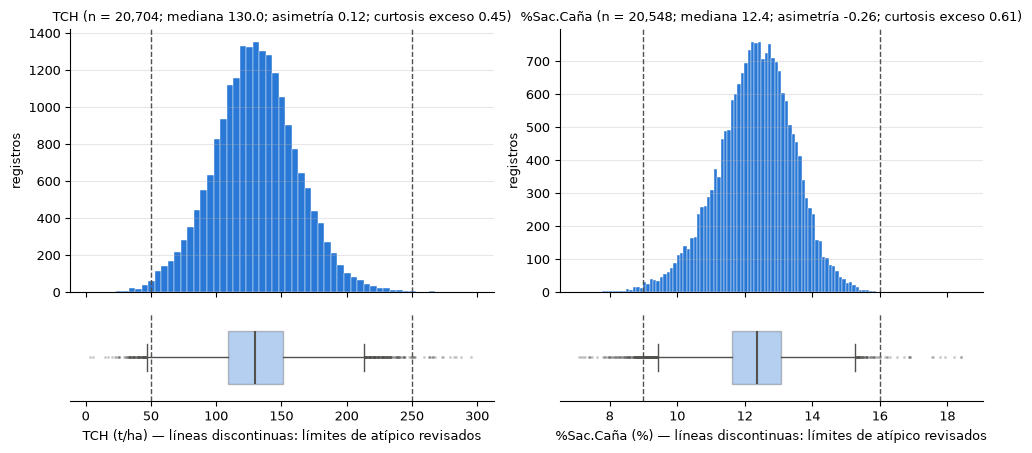

,count,mean,median,std,skew,kurt,< 50 / < 9,> 250 / > 16
TCH,20704.0,130.13,130.00,32.28,0.12,0.45,117,19
%Sac.Caña,20548.0,12.32,12.37,1.15,-0.26,0.61,104,19


In [2]:
hist = filtrar_filas(cargar_historico())
fig, axes = plt.subplots(2, 2, figsize=(10, 4.6), sharex="col", gridspec_kw={"height_ratios": [3, 1]})
for j, (t, unidad, refs, ancho) in enumerate([("TCH", "t/ha", (50, 250), 5), ("%Sac.Caña", "%", (9, 16), 0.1)]):
    v = hist[t].dropna()
    ax = axes[0, j]
    ax.hist(v, bins=np.arange(v.min(), v.max() + ancho, ancho), color=COLORES["serie1"], edgecolor="white", linewidth=0.3)
    for r in refs:
        ax.axvline(r, color=COLORES["tinta"], lw=1, ls="--")
    ax.set_ylabel("registros")
    ax.set_title(f"{t} (n = {len(v):,}; mediana {v.median():.1f}; asimetría {v.skew():.2f}; curtosis exceso {v.kurt():.2f})", fontsize=9)
    ax.grid(axis="y", alpha=0.3)
    ax = axes[1, j]
    ax.boxplot(v, orientation="horizontal", widths=0.6, showfliers=True, patch_artist=True,
               boxprops=dict(facecolor=COLORES["serie1"], alpha=0.35, color=COLORES["tinta"]),
               medianprops=dict(color=COLORES["tinta"], lw=1.5), whiskerprops=dict(color=COLORES["tinta"]),
               capprops=dict(color=COLORES["tinta"]), flierprops=dict(marker=".", ms=2, alpha=0.3, mec=COLORES["tinta"]))
    for r in refs:
        ax.axvline(r, color=COLORES["tinta"], lw=1, ls="--")
    ax.set_yticks([]); ax.spines["left"].set_visible(False)
    ax.set_xlabel(f"{t} ({unidad}) — líneas discontinuas: límites de atípico revisados")
fig.tight_layout()
fig.savefig(FIG_DIR / "informe_distribucion_targets_regresion.png", dpi=200, bbox_inches="tight")
plt.show()

resumen = hist[["TCH", "%Sac.Caña"]].agg(["count", "mean", "median", "std", "skew", "kurt"]).T.round(2)
resumen["< 50 / < 9"] = [(hist["TCH"] < 50).sum(), (hist["%Sac.Caña"] < 9).sum()]
resumen["> 250 / > 16"] = [(hist["TCH"] > 250).sum(), (hist["%Sac.Caña"] > 16).sum()]
display(resumen)

## 2. Matrices de correlación (Spearman, solo train)

Se usa **Spearman**: varias variables son ordinales o discretas (`cortes`, semanas) y hay colas largas (lluvias). Se
calcula **después** de aplicar las reglas fijas aprobadas (p. ej. lluvia 0 → NaN), sobre las filas con dato de cada
par. Regresión: train del notebook 02 (por suerte). Clasificación: train por hacienda.

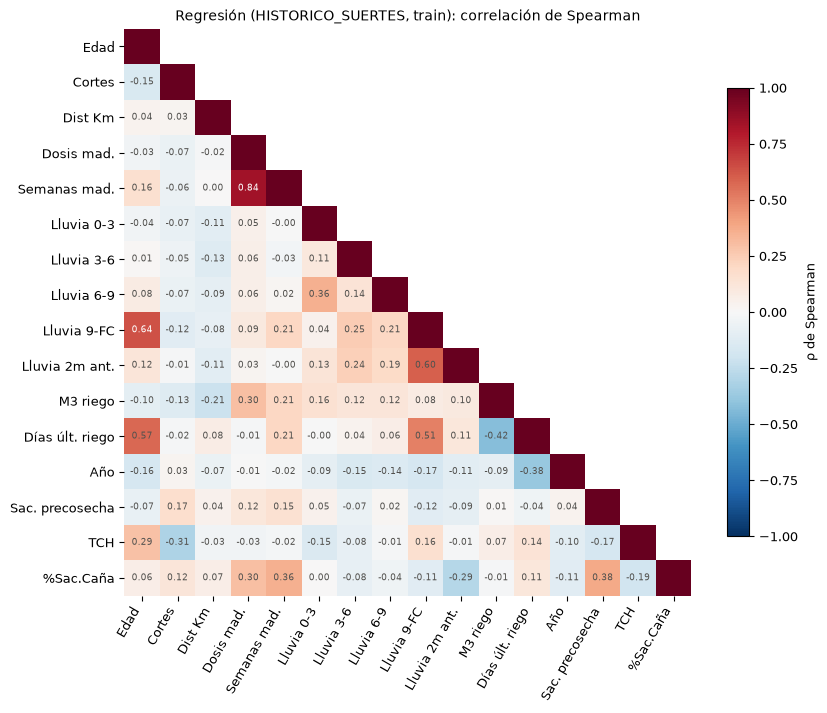

Correlación con los targets (ordenada por |ρ| con TCH):


,TCH,%Sac.Caña
Cortes,-0.31,0.12
Edad,0.29,0.06
Sac. precosecha,-0.17,0.38
Lluvia 9-FC,0.16,-0.11
Lluvia 0-3,-0.15,0.00
Días últ. riego,0.14,0.11
Año,-0.10,-0.11
Lluvia 3-6,-0.08,-0.08
M3 riego,0.07,-0.01
Dosis mad.,-0.03,0.30


In [3]:
def heatmap(c, titulo, archivo, figsize):
    mascara = np.triu(np.ones_like(c, dtype=bool), k=1)
    datos = c.mask(mascara)
    fig, ax = plt.subplots(figsize=figsize)
    im = ax.imshow(datos, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(c)), c.columns, rotation=60, ha="right")
    ax.set_yticks(range(len(c)), c.index)
    for i in range(len(c)):
        for j in range(i + 1):
            val = c.iloc[i, j]
            if i != j and pd.notna(val):
                ax.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=6.5,
                        color="white" if abs(val) > 0.6 else COLORES["tinta"])
    ax.spines[["left", "bottom"]].set_visible(False)
    ax.set_title(titulo, fontsize=10)
    fig.colorbar(im, ax=ax, shrink=0.7, label="ρ de Spearman")
    fig.tight_layout()
    fig.savefig(FIG_DIR / archivo, dpi=200, bbox_inches="tight")
    plt.show()

train_reg, _ = particiones_regresion()
R = ReglasNegocio().fit(train_reg).transform(train_reg)
cols_reg = {"Edad Ult Cos": "Edad", "Cod.Estado #": "Cortes", "Dist Km": "Dist Km", "Dosis Madurante": "Dosis mad.",
            "Semanas mad.": "Semanas mad.", "Lluvias 0 -3": "Lluvia 0-3", "Lluvias tres a seis": "Lluvia 3-6",
            "Lluvias seis a nueve": "Lluvia 6-9", "Luvias 9 -FC": "Lluvia 9-FC", "Lluvias (2 Meses Ant.)": "Lluvia 2m ant.",
            "M3 Riego": "M3 riego", "DDUlt.Riego": "Días últ. riego", "anio": "Año",
            "Sac.Caña Precosecha": "Sac. precosecha", "TCH": "TCH", "%Sac.Caña": "%Sac.Caña"}
Rr = R.join(train_reg[["TCH", "%Sac.Caña"]]) if "TCH" not in R else R
c_reg = Rr[list(cols_reg)].rename(columns=cols_reg).corr(method="spearman")
heatmap(c_reg, "Regresión (HISTORICO_SUERTES, train): correlación de Spearman", "informe_correlacion_regresion.png", (8.5, 7.5))
print("Correlación con los targets (ordenada por |ρ| con TCH):")
display(c_reg[["TCH", "%Sac.Caña"]].drop(["TCH", "%Sac.Caña"]).reindex(c_reg["TCH"].drop(["TCH", "%Sac.Caña"]).abs().sort_values(ascending=False).index).round(2))

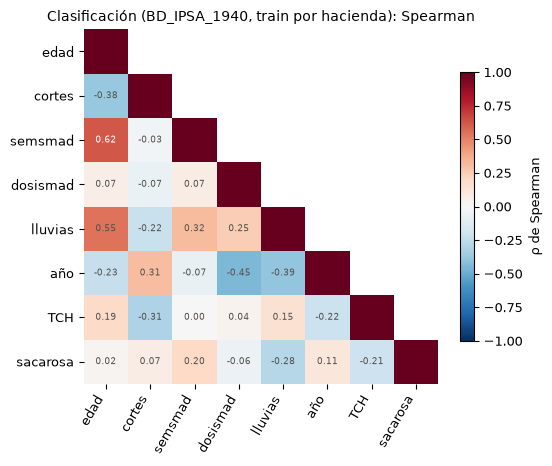

In [4]:
train_clf, test_clf = split_clasificacion(cargar_ipsa())
Rc = ReglasNegocioClasificacion().fit(train_clf[PREDICTORAS_CLASIFICACION]).transform(train_clf[PREDICTORAS_CLASIFICACION])
Rc = Rc.assign(TCH=train_clf["TCH"], sacarosa=train_clf["sacarosa"])
cols_clf = {"edad": "edad", "cortes": "cortes", "semsmad": "semsmad", "dosismad": "dosismad", "lluvias": "lluvias",
            "anio": "año", "TCH": "TCH", "sacarosa": "sacarosa"}
c_clf = Rc[list(cols_clf)].rename(columns=cols_clf).corr(method="spearman")
heatmap(c_clf, "Clasificación (BD_IPSA_1940, train por hacienda): Spearman", "informe_correlacion_clasificacion.png", (5.6, 4.8))

## 3. Importancia de variables de clasificación (logística L1 final)

(a) **Importancia por variable:** máximo |coeficiente| entre clases y columnas de la variable. Las numéricas están
estandarizadas; para variables con varias columnas (`semsmad` en spline, dummies de `mes_cosecha` y `grupo_tenencia`)
el máximo tiende a ser mayor solo por tener más columnas, así que la comparación entre variables es **orientativa**.
(b) **Efecto del mes de cosecha en sacarosa:** coeficiente de "Alto" por mes, contra enero.

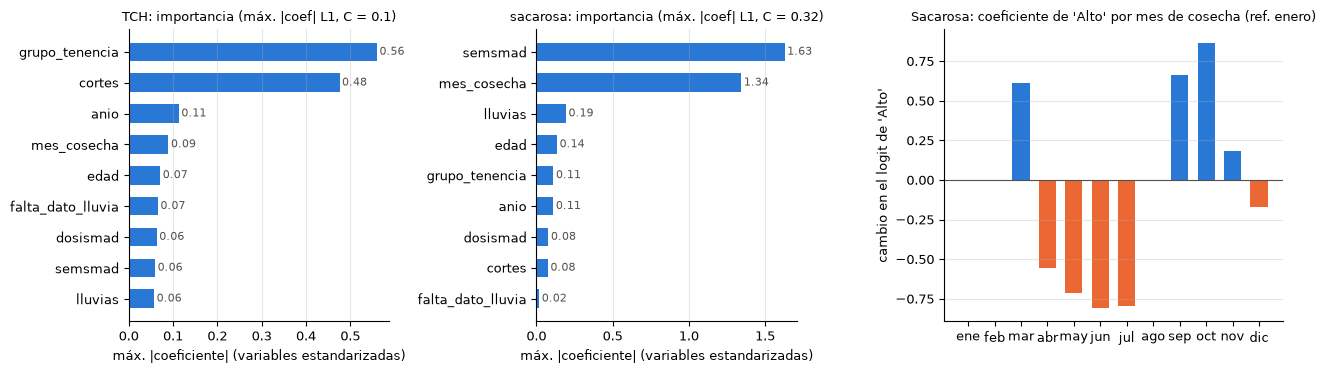

TCH               sacarosa              
                    Alto   Bajo  Medio     Alto   Bajo  Medio
lluvias            0.053 -0.057  0.000   -0.151  0.195  0.000
edad               0.062  0.000 -0.071    0.000  0.136  0.000
cortes            -0.476  0.147  0.000    0.030 -0.076  0.000
anio              -0.113  0.061  0.000    0.022 -0.112  0.000
grupo_tenencia_2  -0.277  0.000  0.000    0.112  0.000 -0.087
grupo_tenencia_3   0.106 -0.560  0.000    0.000  0.000  0.000
mes_cosecha_2      0.000  0.000  0.000    0.000 -0.188  0.003
mes_cosecha_3      0.000  0.000  0.000    0.611 -0.594  0.000
mes_cosecha_4      0.000  0.000  0.000   -0.555  0.103  0.000
mes_cosecha_5      0.000  0.000  0.000   -0.713  0.207  0.000
mes_cosecha_6      0.000  0.000  0.000   -0.808  0.937  0.000
mes_cosecha_7      0.000  0.000  0.000   -0.795  0.123  0.000
mes_cosecha_8      0.000  0.000  0.000    0.000 -0.443  0.000
mes_cosecha_9      0.000  0.000  0.000    0.664 -0.211  0.000
mes_cosecha_10     0.000 -0.090  0.000    0.867 -1.344  0.000
mes_cosecha_11     0.000  0.000  0.000    0.181 -0.147  0.000
mes_cosecha_12     0.000  0.000  0.000   -0.169  0.132  0.000
falta_dato_lluvia  0.000  0.066 -0.053   -0.019  0.014  0.000
dosismad           0.063  0.000 -0.022    0.000 -0.079  0.031
semsmad_sp_0       0.000  0.000  0.000    0.000  0.000  0.000
semsmad_sp_1       0.000  0.000  0.000   -1.628  0.932  0.000
semsmad_sp_2       0.000 -0.060  0.000    0.000  0.000  0.000
semsmad_sp_3       0.000  0.000  0.000    0.505 -0.149  0.000
semsmad_sp_4       0.000  0.000  0.000    0.234  0.000  0.000
semsmad_sp_5       0.000  0.000  0.000    0.000  0.000  0.000
semsmad_sp_6       0.000  0.000  0.000    0.000  0.000  0.000

In [5]:
BASE = ["lluvias", FLAG_LLUVIA, "dosismad", "edad", "cortes", "anio", "semsmad", "grupo_tenencia", "mes_cosecha"]
origen = lambda c: next(v for v in BASE if c == v or c.startswith(v + "_"))
C_FINAL = {"TCH": 0.1, "sacarosa": 0.31622776601683794}
coefs = {}
for t, C in C_FINAL.items():
    X, y, _ = preparar_xy_clf(train_clf, t)
    pipe = Pipeline([("pre", construir_preprocesador_clf("logistica")),
                     ("clf", LogisticRegression(l1_ratio=1, solver="saga", C=C, max_iter=20000, class_weight="balanced"))]).fit(X, y)
    cols = pipe.named_steps["pre"].get_feature_names_out()
    coefs[t] = pd.DataFrame(pipe.named_steps["clf"].coef_, index=pipe.named_steps["clf"].classes_, columns=cols).T

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1, 1, 1.3]})
for ax, t in zip(axes[:2], C_FINAL):
    imp = coefs[t].abs().groupby([origen(c) for c in coefs[t].index]).max().max(axis=1).sort_values()
    ax.barh(imp.index, imp.values, color=COLORES["serie1"], height=0.6)
    for i, v in enumerate(imp.values):
        ax.text(v + imp.max() * 0.01, i, f"{v:.2f}", va="center", fontsize=8, color=COLORES["tinta"])
    ax.set_title(f"{t}: importancia (máx. |coef| L1, C = {C_FINAL[t]:.2g})", fontsize=9.5)
    ax.set_xlabel("máx. |coeficiente| (variables estandarizadas)")
    ax.grid(axis="x", alpha=0.3)
ax = axes[2]
mes = coefs["sacarosa"].filter(like="mes_cosecha_", axis=0)["Alto"]
mes.index = [int(c.split("_")[-1]) for c in mes.index]
mes = pd.concat([pd.Series({1: 0.0}), mes]).sort_index()
nombres = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
ax.bar(nombres, mes.values, color=[COLORES["serie1"] if v >= 0 else COLORES["serie2"] for v in mes.values], width=0.65)
ax.axhline(0, color=COLORES["tinta"], lw=0.8)
ax.set_title("Sacarosa: coeficiente de 'Alto' por mes de cosecha (ref. enero)", fontsize=9.5)
ax.set_ylabel("cambio en el logit de 'Alto'")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / "informe_importancia_clasificacion.png", dpi=200, bbox_inches="tight")
plt.show()
display(pd.concat({t: coefs[t] for t in C_FINAL}, axis=1).round(3))

## 4. Matrices de confusión de los modelos finales (test, 56 haciendas no vistas)

TCH: logística L1 (C = 0.1). Sacarosa: KNN distance + corrección por priors (k = 23). Se muestra el % por fila
(recall de cada clase) y, entre paréntesis, el conteo.

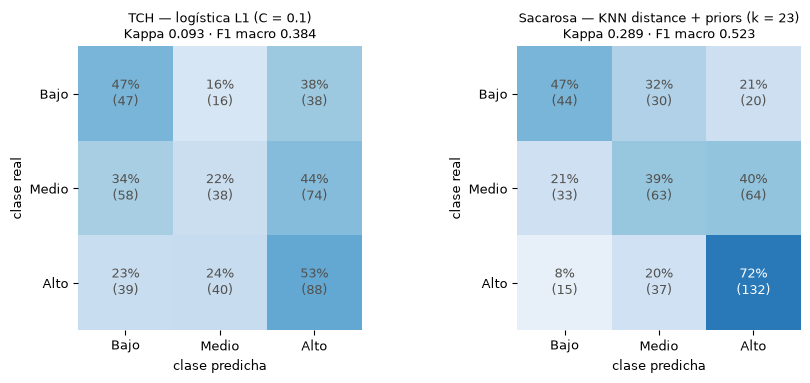

In [6]:
modelos_finales = {
    "TCH — logística L1 (C = 0.1)": ("TCH", Pipeline([("pre", construir_preprocesador_clf("logistica")),
        ("clf", LogisticRegression(l1_ratio=1, solver="saga", C=0.1, max_iter=20000, class_weight="balanced"))])),
    "Sacarosa — KNN distance + priors (k = 23)": ("sacarosa", Pipeline([("pre", construir_preprocesador_clf("knn", target="sacarosa")),
        ("clf", KNNPriorCorregido(n_neighbors=23, weights="distance"))])),
}
fig, axes = plt.subplots(1, 2, figsize=(9, 3.9))
for ax, (titulo, (t, modelo)) in zip(axes, modelos_finales.items()):
    X, y, _ = preparar_xy_clf(train_clf, t)
    X_te, y_te, _ = preparar_xy_clf(test_clf, t)
    pred = modelo.fit(X, y).predict(X_te)
    cm = confusion_matrix(y_te, pred, labels=CLASES)
    pct = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(pct, cmap="Blues", vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{pct[i, j]:.0%}\n({cm[i, j]})", ha="center", va="center", fontsize=9,
                    color="white" if pct[i, j] > 0.55 else COLORES["tinta"])
    ax.set_xticks(range(3), CLASES); ax.set_yticks(range(3), CLASES)
    ax.set_xlabel("clase predicha"); ax.set_ylabel("clase real")
    from sklearn.metrics import cohen_kappa_score, f1_score
    ax.set_title(f"{titulo}\nKappa {cohen_kappa_score(y_te, pred):.3f} · F1 macro {f1_score(y_te, pred, average='macro'):.3f}", fontsize=9.5)
    ax.spines[["left", "bottom"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIG_DIR / "informe_matrices_confusion_finales.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Versiones finales para la plantilla del informe

Reglas de la plantilla: sin títulos dentro de la imagen (el pie va en el documento), partes etiquetadas "(a)",
"(b)", "(c)" y sin bordes externos. Tamaños pensados para una página carta a una columna (ancho útil ≈ 15.6 cm):
Figs. 1 y 2 a ancho completo; Figs. 3 y 4 a media página, lado a lado.

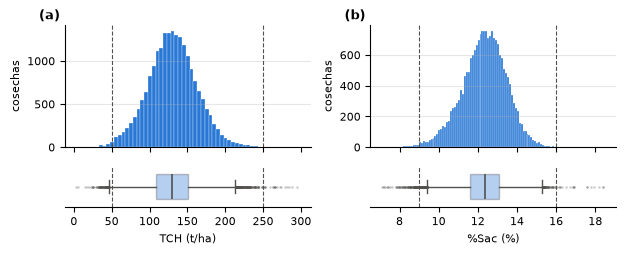

In [7]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline as Pipe
from src.datos import preparar_xy
from src.preprocesamiento import construir_preprocesador

plt.rcParams.update({"font.size": 8})
def etiqueta(ax, txt):
    ax.text(-0.02, 1.02, txt, transform=ax.transAxes, fontsize=9, fontweight="bold", ha="right", va="bottom")

# Fig. 1 — distribución de los targets de regresión
fig, axes = plt.subplots(2, 2, figsize=(6.3, 2.6), sharex="col", gridspec_kw={"height_ratios": [3, 1]})
for j, (t, unidad, refs, ancho, et) in enumerate([("TCH", "t/ha", (50, 250), 5, "(a)"), ("%Sac.Caña", "%", (9, 16), 0.1, "(b)")]):
    v = hist[t].dropna()
    ax = axes[0, j]
    ax.hist(v, bins=np.arange(v.min(), v.max() + ancho, ancho), color=COLORES["serie1"], edgecolor="white", linewidth=0.2)
    for r in refs:
        ax.axvline(r, color=COLORES["tinta"], lw=0.8, ls="--")
    ax.set_ylabel("cosechas"); ax.grid(axis="y", alpha=0.3); etiqueta(ax, et)
    ax = axes[1, j]
    ax.boxplot(v, orientation="horizontal", widths=0.6, patch_artist=True,
               boxprops=dict(facecolor=COLORES["serie1"], alpha=0.35, color=COLORES["tinta"]),
               medianprops=dict(color=COLORES["tinta"], lw=1.2), whiskerprops=dict(color=COLORES["tinta"]),
               capprops=dict(color=COLORES["tinta"]), flierprops=dict(marker=".", ms=1.5, alpha=0.3, mec=COLORES["tinta"]))
    for r in refs:
        ax.axvline(r, color=COLORES["tinta"], lw=0.8, ls="--")
    ax.set_yticks([]); ax.spines["left"].set_visible(False); ax.set_xlabel(f"{t.replace('%Sac.Caña', '%Sac')} ({unidad})")
fig.tight_layout()
fig.savefig(FIG_DIR / "informe_fig1.png", dpi=300, bbox_inches="tight"); plt.show()

/home/opc/final_project/venv/lib64/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1, 2, 3] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


/home/opc/final_project/venv/lib64/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1, 2, 3] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


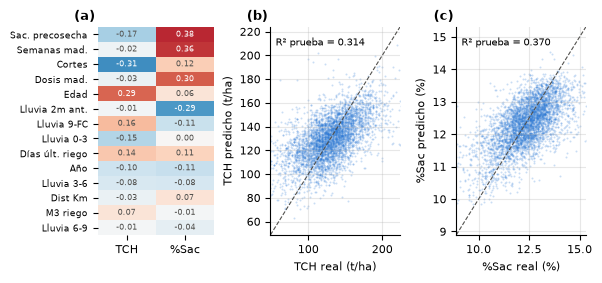

In [8]:
# Fig. 2 — (a) correlación predictoras–targets (regresión, train); (b)(c) real vs. predicho en prueba
train_r, test_r = particiones_regresion()
fig = plt.figure(figsize=(6.3, 2.7))
gs = fig.add_gridspec(1, 3, width_ratios=[0.9, 1, 1], wspace=0.45)
ax = fig.add_subplot(gs[0])
ct = c_reg[["TCH", "%Sac.Caña"]].drop(["TCH", "%Sac.Caña"])
ct = ct.reindex(ct.abs().max(axis=1).sort_values(ascending=False).index)
im = ax.imshow(ct.values, cmap="RdBu_r", vmin=-0.5, vmax=0.5, aspect="auto")
ax.set_xticks([0, 1], ["TCH", "%Sac"]); ax.set_yticks(range(len(ct)), ct.index, fontsize=6.5)
for i in range(len(ct)):
    for j in range(2):
        ax.text(j, i, f"{ct.values[i, j]:.2f}", ha="center", va="center", fontsize=6, color="white" if abs(ct.values[i, j]) > 0.25 else COLORES["tinta"])
ax.spines[["left", "bottom"]].set_visible(False); etiqueta(ax, "(a)")
for k, (t, et, unidad) in enumerate([("TCH", "(b)", "t/ha"), ("%Sac.Caña", "(c)", "%")]):
    X, y, _ = preparar_xy(train_r, t); Xt, yt, _ = preparar_xy(test_r, t)
    m = Pipe([("pre", construir_preprocesador("lineal")), ("lr", LinearRegression())]).fit(X, y)
    pred = m.predict(Xt)
    ax = fig.add_subplot(gs[k + 1])
    ax.scatter(yt, pred, s=2, alpha=0.25, color=COLORES["serie1"], linewidths=0)
    lo, hi = np.percentile(np.r_[yt, pred], [0.2, 99.8])
    ax.plot([lo, hi], [lo, hi], color=COLORES["tinta"], lw=0.8, ls="--")
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
    nom = t.replace("%Sac.Caña", "%Sac")
    ax.set_xlabel(f"{nom} real ({unidad})"); ax.set_ylabel(f"{nom} predicho ({unidad})")
    from sklearn.metrics import r2_score
    ax.text(0.04, 0.95, f"R² prueba = {r2_score(yt, pred):.3f}", transform=ax.transAxes, va="top", fontsize=7)
    ax.grid(alpha=0.3); etiqueta(ax, et)
fig.savefig(FIG_DIR / "informe_fig2.png", dpi=300, bbox_inches="tight"); plt.show()

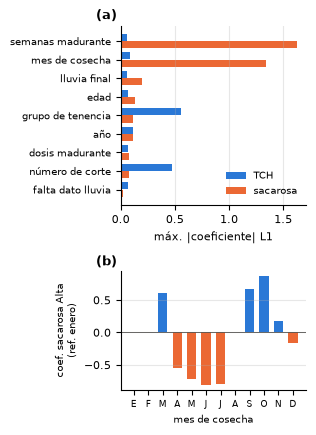

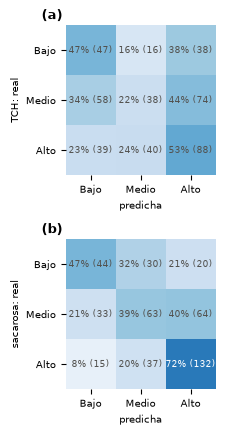

In [9]:
# Fig. 3 — (a) importancia L1 por variable en los dos targets; (b) coeficiente de sacarosa "Alto" por mes
imp = pd.DataFrame({t: coefs[t].abs().groupby([origen(c) for c in coefs[t].index]).max().max(axis=1) for t in C_FINAL})
nombres_var = {"grupo_tenencia": "grupo de tenencia", "cortes": "número de corte", "anio": "año", "mes_cosecha": "mes de cosecha",
               "edad": "edad", FLAG_LLUVIA: "falta dato lluvia", "dosismad": "dosis madurante", "semsmad": "semanas madurante",
               "lluvias": "lluvia final"}
imp = imp.rename(index=nombres_var).sort_values("sacarosa")
fig, axes = plt.subplots(2, 1, figsize=(3.2, 4.4), gridspec_kw={"height_ratios": [1.5, 1]})
ax = axes[0]; yy = np.arange(len(imp))
ax.barh(yy + 0.2, imp["TCH"], height=0.38, color=COLORES["serie1"], label="TCH")
ax.barh(yy - 0.2, imp["sacarosa"], height=0.38, color=COLORES["serie2"], label="sacarosa")
ax.set_yticks(yy, imp.index, fontsize=7); ax.set_xlabel("máx. |coeficiente| L1"); ax.grid(axis="x", alpha=0.3)
ax.legend(frameon=False, fontsize=7, loc="lower right"); etiqueta(ax, "(a)")
ax = axes[1]
ax.bar(range(12), mes.values, color=[COLORES["serie1"] if v >= 0 else COLORES["serie2"] for v in mes.values], width=0.65)
ax.set_xticks(range(12), list("EFMAMJJASOND"))
ax.set_xlabel("mes de cosecha", fontsize=7)
ax.axhline(0, color=COLORES["tinta"], lw=0.6); ax.set_ylabel("coef. sacarosa Alta\n(ref. enero)", fontsize=7)
ax.tick_params(axis="x", labelsize=6.5); ax.grid(axis="y", alpha=0.3); etiqueta(ax, "(b)")
fig.tight_layout()
fig.savefig(FIG_DIR / "informe_fig3.png", dpi=300, bbox_inches="tight"); plt.show()

# Fig. 4 — matrices de confusión de los modelos finales (prueba)
fig, axes = plt.subplots(2, 1, figsize=(3.2, 4.4))
for ax, (titulo, (t, modelo)), et in zip(axes, modelos_finales.items(), ["(a)", "(b)"]):
    X, y, _ = preparar_xy_clf(train_clf, t); X_te, y_te, _ = preparar_xy_clf(test_clf, t)
    pred = modelo.fit(X, y).predict(X_te)
    cm = confusion_matrix(y_te, pred, labels=CLASES); pct = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(pct, cmap="Blues", vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{pct[i, j]:.0%} ({cm[i, j]})", ha="center", va="center", fontsize=6.5,
                    color="white" if pct[i, j] > 0.55 else COLORES["tinta"])
    ax.set_xticks(range(3), CLASES, fontsize=7); ax.set_yticks(range(3), CLASES, fontsize=7)
    ax.set_xlabel("predicha", fontsize=7); ax.set_ylabel(f"{t}: real", fontsize=7)
    ax.spines[["left", "bottom"]].set_visible(False); etiqueta(ax, et)
fig.tight_layout()
fig.savefig(FIG_DIR / "informe_fig4.png", dpi=300, bbox_inches="tight"); plt.show()